In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\ELCOT\Downloads\flights.csv")
df

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336771,336771,2013,9,30,NaN,1455,NaN,NaN,1634,NaN,...,3393,NaN,JFK,DCA,NaN,213,14,55,2013-09-30 14:00:00,Endeavor Air Inc.
336772,336772,2013,9,30,NaN,2200,NaN,NaN,2312,NaN,...,3525,NaN,LGA,SYR,NaN,198,22,0,2013-09-30 22:00:00,Endeavor Air Inc.
336773,336773,2013,9,30,NaN,1210,NaN,NaN,1330,NaN,...,3461,N535MQ,LGA,BNA,NaN,764,12,10,2013-09-30 12:00:00,Envoy Air
336774,336774,2013,9,30,NaN,1159,NaN,NaN,1344,NaN,...,3572,N511MQ,LGA,CLE,NaN,419,11,59,2013-09-30 11:00:00,Envoy Air


In [3]:
df.shape

(336776, 21)

In [4]:
df.columns

Index(['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'name'],
      dtype='str')

In [5]:
df.dtypes

id                  int64
year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier               str
flight              int64
tailnum               str
origin                str
dest                  str
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour             str
name                  str
dtype: object

In [6]:
df.isnull().sum()

id                   0
year                 0
month                0
day                  0
dep_time          8255
sched_dep_time       0
dep_delay         8255
arr_time          8713
sched_arr_time       0
arr_delay         9430
carrier              0
flight               0
tailnum           2512
origin               0
dest                 0
air_time          9430
distance             0
hour                 0
minute               0
time_hour            0
name                 0
dtype: int64

In [10]:
df['month'] = df['month'].fillna(df['month'].mode()[0])
df['year'] = df['year'].fillna(df['year'].median())
df['carrier'] = df['carrier'].fillna(df['carrier'].mode()[0])
df['origin'] = df['origin'].fillna(df['origin'].mode()[0])
df['dest'] = df['dest'].fillna(df['dest'].mode()[0])
df['name'] = df['name'].fillna(df['name'].mode()[0])

In [11]:
freq = df['carrier'].value_counts()
print(freq)

carrier
UA    58665
B6    54635
EV    54173
DL    48110
AA    32729
MQ    26397
US    20536
9E    18460
WN    12275
VX     5162
FL     3260
AS      714
F9      685
YV      601
HA      342
OO       32
Name: count, dtype: int64


In [12]:
percentage = df['carrier'].value_counts(normalize=True) * 100
print(percentage)

carrier
UA    17.419590
B6    16.222949
EV    16.085766
DL    14.285460
AA     9.718329
MQ     7.838148
US     6.097822
9E     5.481388
WN     3.644856
VX     1.532770
FL     0.968002
AS     0.212010
F9     0.203399
YV     0.178457
HA     0.101551
OO     0.009502
Name: proportion, dtype: float64


In [13]:
print(df['carrier'].mode()[0])

UA


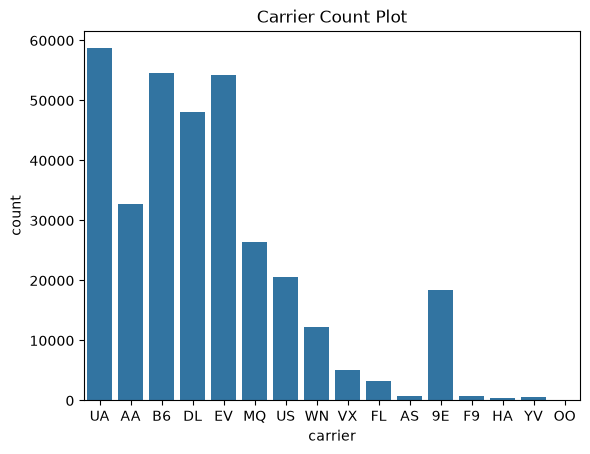

In [14]:
sns.countplot(x='carrier', data=df)
plt.title("Carrier Count Plot")
plt.show()

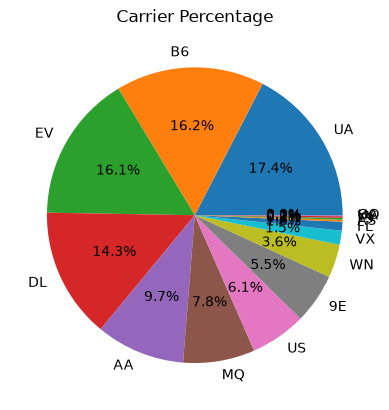

In [15]:
df['carrier'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Carrier Percentage")
plt.show()